# 04 · Exploratory Data Analysis & Weather-Demand Patterns
**Owner:** P4 (EDA, Presentation Chart Set & Review 1 Deck) · **Tasks:** T19 Exploratory Data Analysis, T20 Presentation Chart Set ·
**Rubric:** Review 1: EDA & visualization (3 points), Presentation (3 points)

---

### Executive Overview & Analytical Objectives
This notebook delivers the end-to-end Exploratory Data Analysis (EDA) investigating the relationship between meteorological phenomena and food delivery ordering patterns in **Coimbatore, Tamil Nadu**.

**Core Analytical Questions:**
1. **Demand Distributions:** What does the baseline distribution of daily orders and transaction values look like across the 3-year observation window (2023–2026)?
2. **Temporal Cadence:** How do order volumes fluctuate across weekdays (Mon–Sun) and operational meal slots (Lunch, Evening Snacks, Dinner)?
3. **Meteorological Impact:** How does rain change order volume, and does the effect differ between weekdays and weekends? Are the differences statistically significant?
4. **Item & Category Substitutions:** How does weather alter consumer culinary preferences? Which menu items surge or plunge during monsoonal downpours versus extreme heat episodes?
5. **Multi-variable Correlations:** What are the linear and monotonic relationships between weather variables (precipitation, humidity, temperature, wind, daylight) and order volumes/revenue?

**Data Integrity Note:**
Weather data is **real reanalysis data** fetched from the Open-Meteo Historical Weather API (`data/raw/weather.csv`, P1). Food order volumes and customer baskets are **synthetic transactions** from `src/generator.py`, whose parameters are derived from real Hotel Chinthamani Swiggy orders, the team survey and real outlet prices (`docs/generator.md`, validated in `docs/validation.md`). Observations below therefore describe the evidence-based rules as they appear in three years of data.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

# Configure environment root and plot style
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import plotstyle
import eda

plotstyle.apply()
C = plotstyle.C

# Output directory for presentation-ready charts (T20)
RESULTS = ROOT / "results/eda"
RESULTS.mkdir(parents=True, exist_ok=True)
SLIDES_FIGS = ROOT / "slides/review1/figures"
SLIDES_FIGS.mkdir(parents=True, exist_ok=True)

print(f"Environment initialized. Root directory: {ROOT}")

Environment initialized. Root directory: /Users/deepak/projects/BA-Project/weather-food-orders


## 1. Data Ingestion & Quality Audit

We ingest five foundational datasets from `data/raw/`:
* `daily_orders.csv`: 1,097 daily records combining meteorological observations, calendar tags, and order totals.
* `orders.csv`: 182,696 granular transaction records with timestamps, meal slots, baskets, and basket order values.
* `weather.csv`: 1,097 daily weather records from Open-Meteo API.
* `weather_hourly.csv`: 26,328 hourly meteorological readings.
* `menu.csv`: 80 items (70 real Hotel Chinthamani dishes + 10 sourced snacks and drinks) with category, price and weather affinity.

In [2]:
data = eda.load_eda_data(ROOT)
daily = data["daily"]
orders = data["orders"]
weather = data["weather"]
weather_hourly = data["weather_hourly"]
menu = data["menu"]

print("=== DATASET HEALTH & INTEGRITY AUDIT ===")
print(f"Daily Orders:    {daily.shape[0]:,} rows, {daily.shape[1]} columns ({daily['date'].min().date()} to {daily['date'].max().date()})")
print(f"Transactions:    {orders.shape[0]:,} rows, {orders.shape[1]} columns")
print(f"Daily Weather:   {weather.shape[0]:,} rows, {weather.shape[1]} columns")
print(f"Hourly Weather:  {weather_hourly.shape[0]:,} rows, {weather_hourly.shape[1]} columns")
print(f"Menu Catalog:    {menu.shape[0]} items across {menu['category'].nunique()} categories")

# Assert zero nulls in analytical fields
assert daily["order_count"].isna().sum() == 0, "Missing order counts in daily dataset!"
assert orders["order_value"].isna().sum() == 0, "Missing order values in transactions dataset!"
assert daily["precip_mm"].isna().sum() == 0, "Missing precipitation measurements!"
print("Data integrity check passed: 0 missing values in core analytical features; contiguous date index.")

=== DATASET HEALTH & INTEGRITY AUDIT ===
Daily Orders:    1,097 rows, 31 columns (2023-09-24 to 2026-09-24)
Transactions:    182,696 rows, 8 columns
Daily Weather:   1,097 rows, 11 columns
Hourly Weather:  26,328 rows, 4 columns
Menu Catalog:    80 items across 10 categories
Data integrity check passed: 0 missing values in core analytical features; contiguous date index.


## 2. Order Volume Distribution Analysis (T19)

We evaluate the parametric and non-parametric properties of the daily order count distribution.

In [3]:
dist_stats = eda.get_order_distribution_stats(daily)

print("=== DAILY ORDER VOLUME SUMMARY STATISTICS ===")
for k, v in dist_stats.items():
    if k != "regime_stats":
        print(f"• {k:16s}: {v:,.2f}" if isinstance(v, float) else f"• {k:16s}: {v}")

print("\n=== SUMMARY STATISTICS BY AMBIENT REGIME ===")
display(dist_stats["regime_stats"].round(2))

=== DAILY ORDER VOLUME SUMMARY STATISTICS ===
• count           : 1097
• mean            : 166.54
• std             : 69.04
• min             : 73
• p25             : 112.00
• median          : 139.00
• p75             : 234.00
• p95             : 293.00
• max             : 354
• iqr             : 122.00
• skewness        : 0.74
• kurtosis        : -0.82

=== SUMMARY STATISTICS BY AMBIENT REGIME ===


,count,mean,std,median,p25,p75,iqr
regime,,,,,,,
hot,265,177.20,83.76,128.0,106.0,265.0,159.0
normal,503,169.48,78.52,121.0,104.0,253.0,149.0
rainy,329,153.47,23.79,151.0,135.0,169.0,34.0


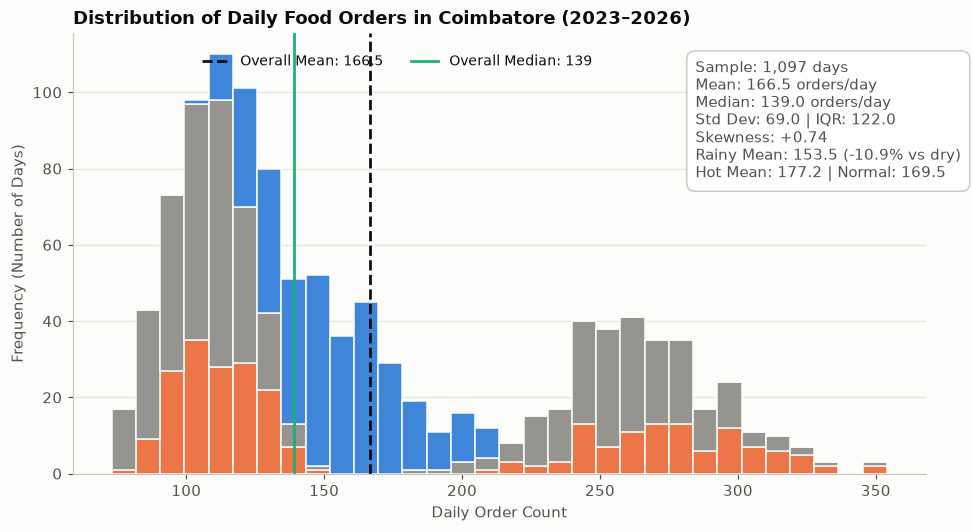

In [4]:
fig01 = eda.plot_fig01_order_distribution(daily, RESULTS / "eda_01_order_distribution.png")
eda.save_fig(fig01, SLIDES_FIGS / "eda_01_order_distribution.png")
plt.show()

### Observations on Daily Order Volume
* **Central Tendency & Spread:** Over the 1,097 days, daily orders average **166.5 orders/day** (SD **69.0**). The median is **139 orders/day**, IQR **122** (25th percentile 112; 75th percentile 234).
* **Two-Humped Shape:** Skewness is **+0.74** and kurtosis **-0.82**: the distribution is a mix of a weekday hump (~110-170) and a weekend hump (~220-300), with a maximum of **354 orders**.
* **Regime Divergence:**
  * **Rainy days ($\ge 2.5$ mm):** mean **153.5 orders/day** with a much smaller spread (SD 23.8) - rain pulls weekdays up and weekends down.
  * **Hot days ($T_{\max} \ge 33^\circ$C):** mean **177.2 orders/day**.
  * **Normal days:** mean **169.5 orders/day**.

## 3. Customer Basket & Monetary Value Distributions (T19)

Next, we analyze the structure of the 182,696 individual customer transactions: basket sizes and total spend per order.

In [5]:
basket_stats = eda.get_basket_and_value_stats(orders)

print("=== TRANSACTION & BASKET METRICS ===")
print(f"Total Transactions: {basket_stats['total_orders']:,}")
print(f"Average Basket Size: {basket_stats['mean_basket_size']:.2f} items")
print(f"Average Order Value: ₹{basket_stats['mean_order_value']:.2f} (Median: ₹{basket_stats['median_order_value']:.2f}, Std: ₹{basket_stats['std_order_value']:.2f})")
print(f"IQR Order Value: ₹{basket_stats['p25_value']:.0f} to ₹{basket_stats['p75_value']:.0f} (95th percentile: ₹{basket_stats['p95_value']:.0f})")

print("\n=== METRICS BY MEAL SLOT ===")
display(basket_stats["meal_slot_stats"].round(2))

=== TRANSACTION & BASKET METRICS ===
Total Transactions: 182,696
Average Basket Size: 1.73 items
Average Order Value: ₹319.93 (Median: ₹255.00, Std: ₹302.93)
IQR Order Value: ₹146 to ₹303 (95th percentile: ₹849)

=== METRICS BY MEAL SLOT ===


,orders,share_pct,mean_val,median_val,std_val,mean_items
meal_slot,,,,,,
Dinner,30629,16.77,322.52,259.0,308.33,1.73
Evening Snacks,17665,9.67,320.23,254.0,302.76,1.74
Lunch,134402,73.57,319.30,256.0,301.70,1.73


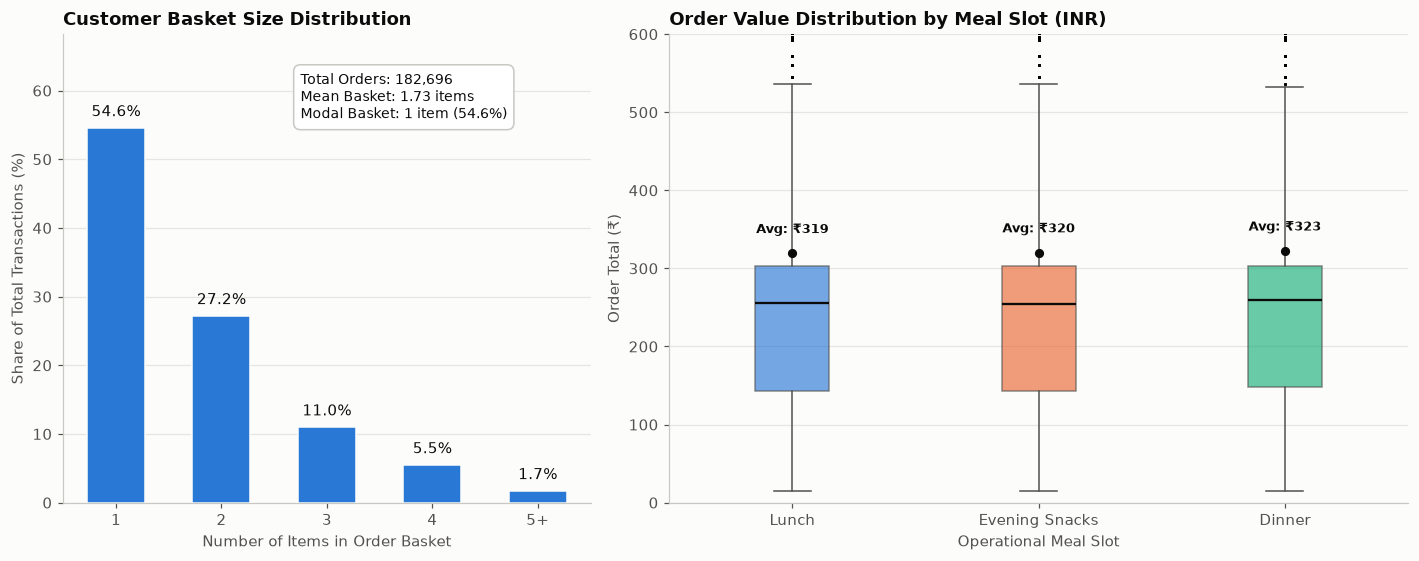

In [6]:
fig02 = eda.plot_fig02_basket_and_value(orders, RESULTS / "eda_02_basket_and_value.png")
eda.save_fig(fig02, SLIDES_FIGS / "eda_02_basket_and_value.png")
plt.show()

### Observations on Basket Size & Monetary Value
* **Basket Architecture:** Single-item orders dominate (**54.6%**), as in the real Swiggy report (65% of food orders). 2-item baskets are **27.2%**, 3 items **11.0%**, 4+ items **7.2%**. Mean basket: **1.73 items**.
* **Financial Value Dispersion:** Order value averages **₹320** (median **₹255**); the interquartile span is **₹146 to ₹303**, with large group orders up to ₹2,979.
* **Meal Slot Monetization:** Spend is nearly identical across slots (Lunch ₹319, Evening Snacks ₹320, Dinner ₹323) because every slot mixes real restaurant meals with cheaper snack/drink orders.

## 4. Weekday-Wise Demand Analysis (T19)

We evaluate customer ordering rhythm across the seven days of the week.

In [7]:
dow_summary = eda.get_weekday_stats(daily)
display(dow_summary.round(2))

,days,mean,std,median,min,max,pct_vs_mon_thu
dow_name,,,,,,,
Mon,157,123.64,32.01,113.0,77,213,-0.21
Tue,157,125.90,31.07,118.0,73,213,1.62
Wed,157,123.78,31.79,116.0,79,209,-0.09
Thu,157,122.26,29.48,115.0,75,200,-1.32
Fri,156,223.68,63.25,245.0,109,332,80.54
Sat,156,225.01,64.88,247.5,109,354,81.61
Sun,157,222.25,65.76,247.0,107,346,79.38


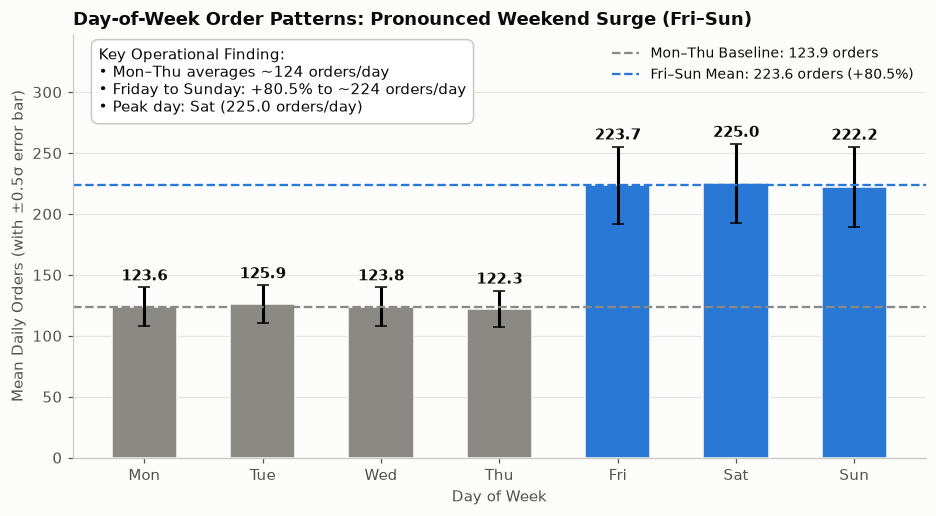

In [8]:
fig03 = eda.plot_fig03_weekday_patterns(daily, RESULTS / "eda_03_weekday_patterns.png")
eda.save_fig(fig03, SLIDES_FIGS / "eda_03_weekday_patterns.png")
plt.show()

### Observations on Day-of-Week Patterns
* **Weekday Stability (Mon–Thu):** Volume is flat from Monday to Thursday at about **124 orders/day** (Mon 123.6, Tue 125.9, Wed 123.8, Thu 122.3).
* **Weekend Demand Surge (Fri–Sun):** Friday **223.7**, Saturday **225.0**, Sunday **222.2** orders/day - about **+80%** over Mon–Thu. The size comes from the real Swiggy weekend effect (x2.47 on dry days).
* **Operational Implication:** Two staffing tiers - baseline Monday–Thursday, roughly 1.8x capacity Friday–Sunday on dry days (rain changes this; see section 6).

## 5. Hourly Order Patterns & Operational Meal Windows (T19)

We examine the temporal concentration of customer orders across the 24 hours of the day.

In [9]:
hourly_counts = orders["hour"].value_counts().sort_index()
hourly_df = pd.DataFrame({"hour": hourly_counts.index, "orders": hourly_counts.values})
hourly_df["share_pct"] = (hourly_df["orders"] / len(orders) * 100).round(2)
display(hourly_df.T)

,0,1,2,3,4,5,6,7,8,9,10,11
hour,11.00,12.0,13.00,14.00,15.0,16.00,17.00,18.0,19.00,20.0,21.00,22.00
orders,20322.00,36729.0,35231.00,26770.00,15350.0,4650.00,5157.00,7858.0,5545.00,15172.0,4736.00,5176.00
share_pct,11.12,20.1,19.28,14.65,8.4,2.55,2.82,4.3,3.04,8.3,2.59,2.83


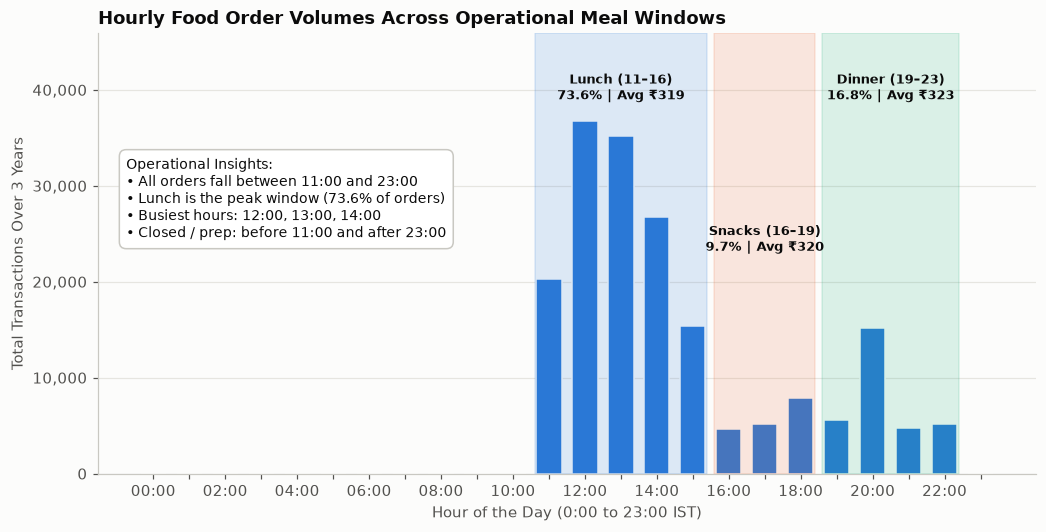

In [10]:
fig04 = eda.plot_fig04_hourly_meal_slots(orders, RESULTS / "eda_04_hourly_meal_slots.png")
eda.save_fig(fig04, SLIDES_FIGS / "eda_04_hourly_meal_slots.png")
plt.show()

### Observations on Hourly Rhythm & Meal Slots
* **Trading Hours:** All orders fall between **11:00 and 23:00**, the real outlet's trading hours (there is no breakfast slot).
* **Lunch Dominates:** **73.6%** of orders arrive 11:00–16:00, peaking at 12:00 and 13:00. Dinner (19:00–23:00) takes **16.8%** with a spike at 20:00; the evening snack window (16:00–19:00) **9.7%**.
* **Prep Windows:** Before 11:00 and 15:00–16:00 are the natural restocking and prep windows.

## 6. Comparative Analysis: Rainy vs. Dry Weather Conditions (T19)

We evaluate the impact of rainfall on order volume, classifying days by precipitation thresholds:
* **Dry:** $\text{precip} < 2.5$ mm (768 days, 70.0% of sample)
* **Moderate Rain:** $2.5 \text{ mm} \le \text{precip} < 15.0$ mm (262 days, 23.9% of sample)
* **Heavy Rain:** $\text{precip} \ge 15.0$ mm (67 days, 6.1% of sample)

In [11]:
rain_stats = eda.get_rain_vs_dry_stats(daily)

print("=== STATISTICAL COMPARISON: RAINY VS DRY DAYS ===")
print(f"• Dry Days Mean:       {rain_stats['dry_mean']:.2f} orders/day (n = {int((~daily['is_rainy']).sum())})")
print(f"• Rainy Days Mean:     {rain_stats['rainy_mean']:.2f} orders/day (n = {int(daily['is_rainy'].sum())})")
print(f"• Absolute Difference: {rain_stats['absolute_diff']:+.2f} orders/day")
print(f"• Relative Change:     {rain_stats['lift_pct']:+.2f}%")
print(f"• Welch's t-test:      t = {rain_stats['t_statistic']:.4f}, p = {rain_stats['t_pvalue']:.4e}")
print(f"• Mann-Whitney U test: U = {rain_stats['mwu_statistic']:,.1f}, p = {rain_stats['mwu_pvalue']:.4e}")

print("\n=== BREAKDOWN BY PRECIPITATION CATEGORY ===")
display(rain_stats["rain_category_summary"].round(2))

=== STATISTICAL COMPARISON: RAINY VS DRY DAYS ===
• Dry Days Mean:       172.14 orders/day (n = 768)
• Rainy Days Mean:     153.47 orders/day (n = 329)
• Absolute Difference: -18.68 orders/day
• Relative Change:     -10.85%
• Welch's t-test:      t = -5.8668, p = 6.0119e-09
• Mann-Whitney U test: U = 143,348.5, p = 4.0289e-04

=== BREAKDOWN BY PRECIPITATION CATEGORY ===


,days,mean,std,median,p25,p75,lift_vs_dry_pct
rain_category,,,,,,,
Dry (<2.5mm),768,172.14,80.40,122.5,105.0,255.25,0.00
Heavy Rain (>=15mm),67,149.03,23.85,149.0,131.0,165.00,-13.43
Moderate Rain (2.5-15mm),262,154.60,23.68,152.0,137.0,169.00,-10.19


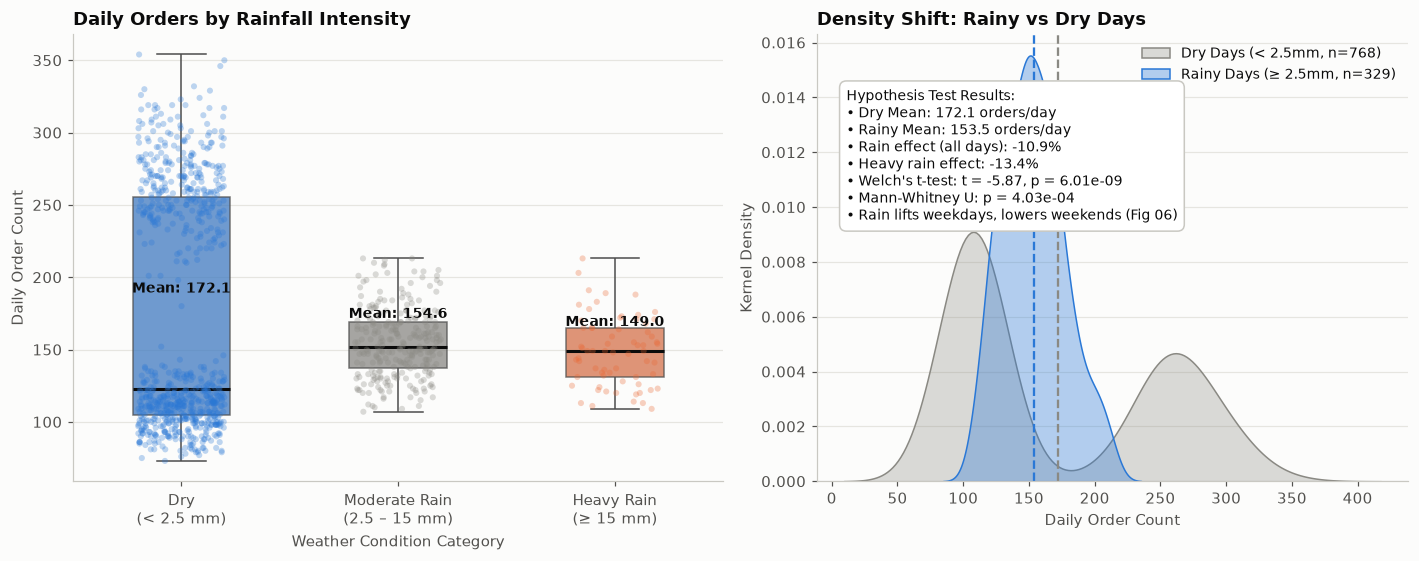

In [12]:
fig05 = eda.plot_fig05_rain_vs_dry_comparison(daily, RESULTS / "eda_05_rain_vs_dry_comparison.png")
eda.save_fig(fig05, SLIDES_FIGS / "eda_05_rain_vs_dry_comparison.png")
plt.show()

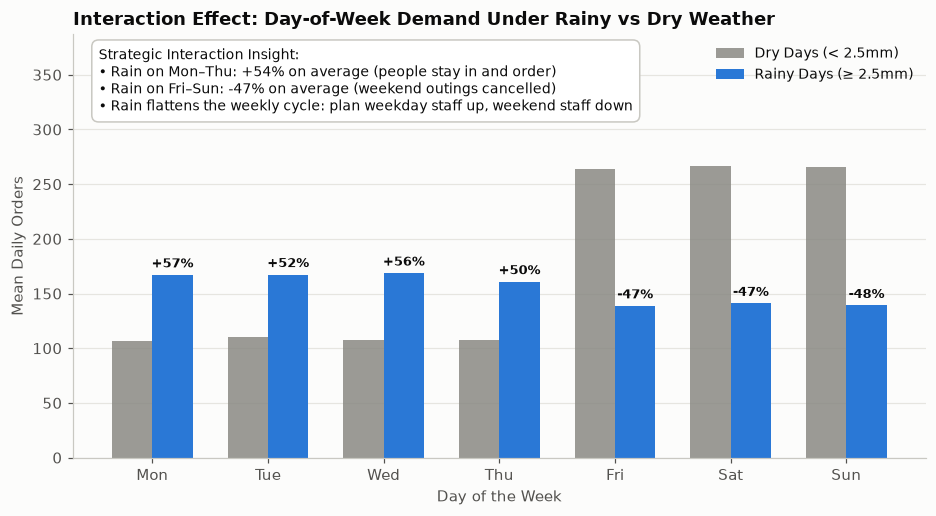

In [13]:
fig06 = eda.plot_fig06_weekday_rain_interaction(daily, RESULTS / "eda_06_weekday_rain_interaction.png")
eda.save_fig(fig06, SLIDES_FIGS / "eda_06_weekday_rain_interaction.png")
plt.show()

### Observations on Rainfall Effects & Day-of-Week Interaction
* **Pooled Effect Is Negative:** Rainy days average **153.5 orders/day** against **172.1** on dry days (**-10.9%**, Welch $t = -5.87$, $p = 6.0 \times 10^{-9}$; Mann-Whitney $p = 4.0 \times 10^{-4}$). Moderate rain averages 154.6 (-10.2%), heavy rain 149.0 (-13.4%).
* **But Rain Works in Opposite Directions by Day Type (the key finding):**
  * **Mon–Thu:** rain lifts orders from **107.9 to 165.9** (**+54%**) - people stay in and order.
  * **Fri–Sun:** rain cuts orders from **265.5 to 139.6** (**-47%**) - weekend outings that end in a takeaway are cancelled.
  * The pooled figure hides both effects; models need a rain x weekend term (see 05_model).
* **Rain Flattens the Week:** On rainy days the spread of daily orders falls to SD 23.8 from 80.4 on dry days.
* **Evidence:** both directions come from the real Swiggy orders (x1.56 on rainy weekdays, x0.54 on rainy weekends); the survey agrees on the weekend half.

## 7. Menu Item & Category Weather Substitutions (T19)

Beyond aggregate order volumes, weather dramatically transforms consumer culinary choices. We unnest the 182,696 orders into individual dishes and evaluate preference shifts.

In [14]:
item_shift, cat_regime_pct = eda.get_item_and_category_shifts(orders, daily, menu)

print("=== TOP 5 ITEMS SURGING ON RAINY DAYS ===")
display(item_shift.sort_values("relative_lift_pct", ascending=False)[
    ["item_name", "category", "weather_affinity", "price", "dry_freq", "rain_freq", "relative_lift_pct"]
].head(5).round(3))

print("\n=== TOP 5 ITEMS PLUNGING ON RAINY DAYS (HEAT DRIVERS) ===")
display(item_shift.sort_values("relative_lift_pct", ascending=True)[
    ["item_name", "category", "weather_affinity", "price", "dry_freq", "rain_freq", "relative_lift_pct"]
].head(5).round(3))

print("\n=== MENU CATEGORY SHARE ACROSS REGIMES (%) ===")
display(cat_regime_pct.round(2))

=== TOP 5 ITEMS SURGING ON RAINY DAYS ===


,item_name,category,weather_affinity,price,dry_freq,rain_freq,relative_lift_pct
72,Samosa,Snacks,hot_comfort,35,0.027,0.118,334.832
71,Coffee,Hot Beverages,hot_comfort,42,0.037,0.115,211.013
73,Pakora,Snacks,hot_comfort,36,0.026,0.077,200.103
74,Bajji,Snacks,hot_comfort,29,0.028,0.076,168.450
70,Chai,Hot Beverages,hot_comfort,38,0.038,0.097,155.231



=== TOP 5 ITEMS PLUNGING ON RAINY DAYS (HEAT DRIVERS) ===


,item_name,category,weather_affinity,price,dry_freq,rain_freq,relative_lift_pct
78,Fresh Lime Juice,Cold Drinks & Desserts,cold_refresh,100,0.092,0.021,-77.177
77,Cold Coffee,Cold Drinks & Desserts,cold_refresh,75,0.095,0.040,-58.178
79,Buttermilk,Cold Drinks & Desserts,cold_refresh,48,0.065,0.031,-52.679
76,Ice Cream,Cold Drinks & Desserts,cold_refresh,79,0.169,0.098,-42.231
48,Mutton Dum Biryani,Biryani & Rice,neutral,488,0.005,0.004,-19.757



=== MENU CATEGORY SHARE ACROSS REGIMES (%) ===


regime,hot,normal,rainy
category,,,
Biryani & Rice,3.52,6.71,5.05
Breads & Tiffin,2.11,4.28,3.15
Chinese,3.44,6.51,4.92
Cold Drinks & Desserts,47.22,11.28,10.66
Egg,1.65,3.18,2.43
Hot Beverages,4.63,4.23,11.92
Meals,12.83,24.26,17.85
Snacks,7.84,7.36,19.04
Soups,10.18,19.67,15.62


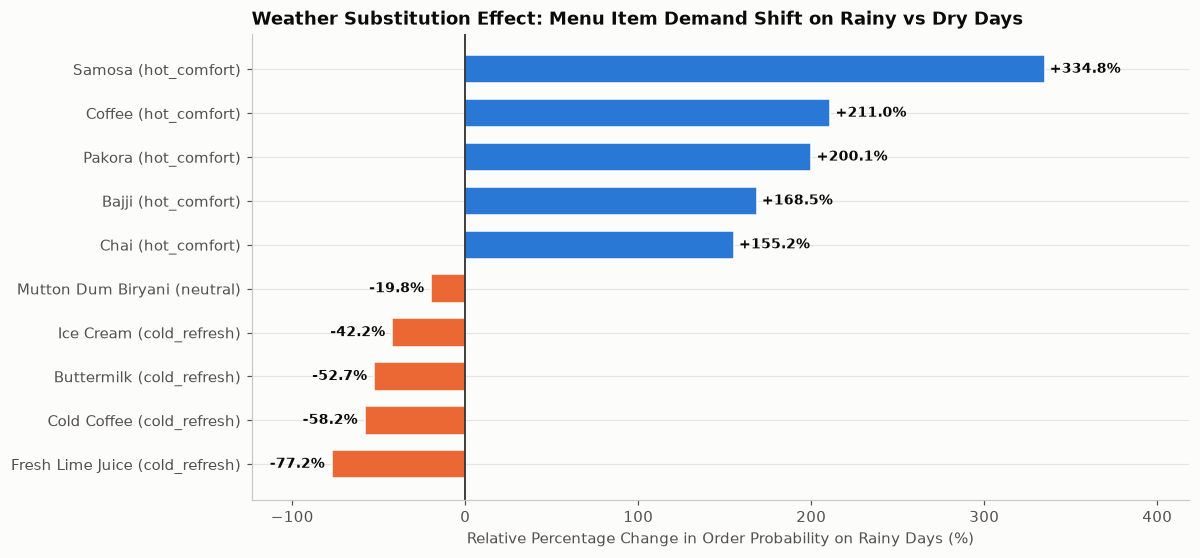

In [15]:
fig07 = eda.plot_fig07_rainy_item_spikers(item_shift, RESULTS / "eda_07_item_rain_spikers.png")
eda.save_fig(fig07, SLIDES_FIGS / "eda_07_item_rain_spikers.png")
plt.show()

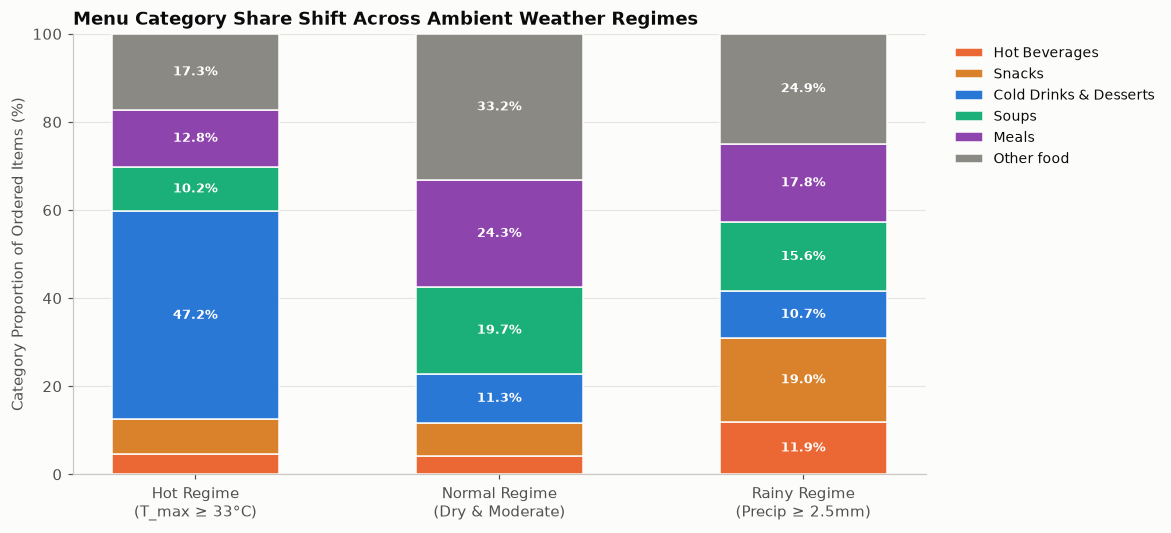

In [16]:
fig08 = eda.plot_fig08_category_regime_shifts(cat_regime_pct, RESULTS / "eda_08_category_regime_shifts.png")
eda.save_fig(fig08, SLIDES_FIGS / "eda_08_category_regime_shifts.png")
plt.show()

### Observations on Item & Category Substitutions
* **The Comfort Surge (rainy vs dry share of items):** Samosa **+335%**, Coffee **+211%**, Pakora **+200%**, Bajji **+168%**, Chai **+155%**, Vada **+40%** - the snacks survey respondents name for rainy days (Q9).
* **The Cold Drink Collapse:** Fresh Lime Juice **-77%**, Cold Coffee **-58%**, Buttermilk **-53%**, Ice Cream **-42%**.
* **Category Regime Shifts:**
  * **Cold Drinks & Desserts:** **47.2%** of items on hot days vs ~11% on normal and rainy days (survey Q10: ice cream, lime juice, cold coffee).
  * **Snacks:** **19.0%** on rainy days vs ~7-8% otherwise; **Hot Beverages** 11.9% vs ~4%.
  * **Soups:** 15.6% on rainy days vs 10.2% on hot days (real Swiggy soup tilt).
  * **Restaurant meals** shrink in share on hot and rainy days only because snack/drink orders grow; the food baskets themselves are the real Swiggy ones.

## 8. Weather-Orders Correlation Analysis & Heatmap (T19)

We evaluate linear (Pearson $r$) and monotonic (Spearman $\rho$) correlations across daily weather metrics, order counts, and financial turnover.

In [17]:
pearson_corr, spearman_corr = eda.get_correlation_matrix(daily)

print("=== CORRELATION WITH DAILY ORDER COUNT ===")
corr_summary = pd.DataFrame({
    "Pearson (r)": pearson_corr["order_count"],
    "Spearman (rho)": spearman_corr["order_count"]
}).sort_values("Pearson (r)", ascending=False)
display(corr_summary.round(3))

=== CORRELATION WITH DAILY ORDER COUNT ===


,Pearson (r),Spearman (rho)
order_count,1.000,1.000
total_revenue,0.938,0.919
temp_mean_c,0.085,0.025
temp_max_c,0.082,0.016
temp_min_c,0.035,0.049
mean_order_val,0.015,-0.034
wind_max_kmh,0.007,0.011
daylight_s,0.007,0.042
humidity_mean_pct,-0.100,0.012
precip_mm,-0.101,0.064


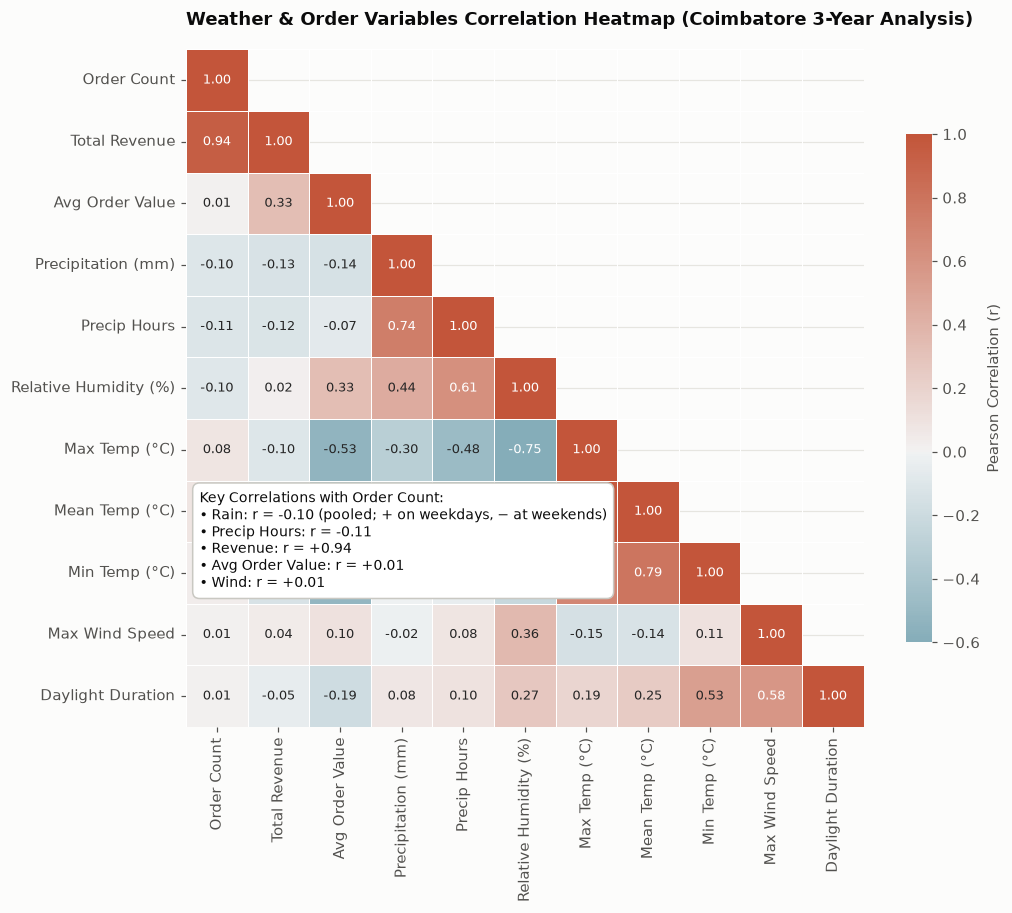

In [18]:
fig09 = eda.plot_fig09_weather_orders_heatmap(daily, RESULTS / "eda_09_weather_orders_heatmap.png")
eda.save_fig(fig09, SLIDES_FIGS / "eda_09_weather_orders_heatmap.png")
plt.show()

### Observations on Weather-Orders Correlation Matrix
* **Pooled Correlations Are Weak - and Misleading:** Precipitation has $r = -0.10$ with order count (Spearman $+0.06$), precipitation hours $r = -0.11$. This is the pooled rain effect cancelling out: on weekdays alone the rank correlation of rain with orders is clearly positive (tested in `tests/test_eda.py`), at weekends negative.
* **Order Count vs Total Revenue:** $r = +0.94$ - volume drives revenue.
* **Average Order Value:** essentially unrelated to volume ($r = +0.01$).
* **Negligible Factors:** wind ($r = +0.01$) and daylight ($r = +0.01$) have no bearing on demand.
* **Lesson:** a correlation matrix cannot show an interaction; Fig 06 and the models with `rain_x_weekend` can.

## 9. Longitudinal Profile & Three-Year Dynamics (T19)

We visualize the entire 1,097-day timeline from September 24, 2023 to September 24, 2026, mapping daily order volumes against monsoonal precipitation and temperature cycles.

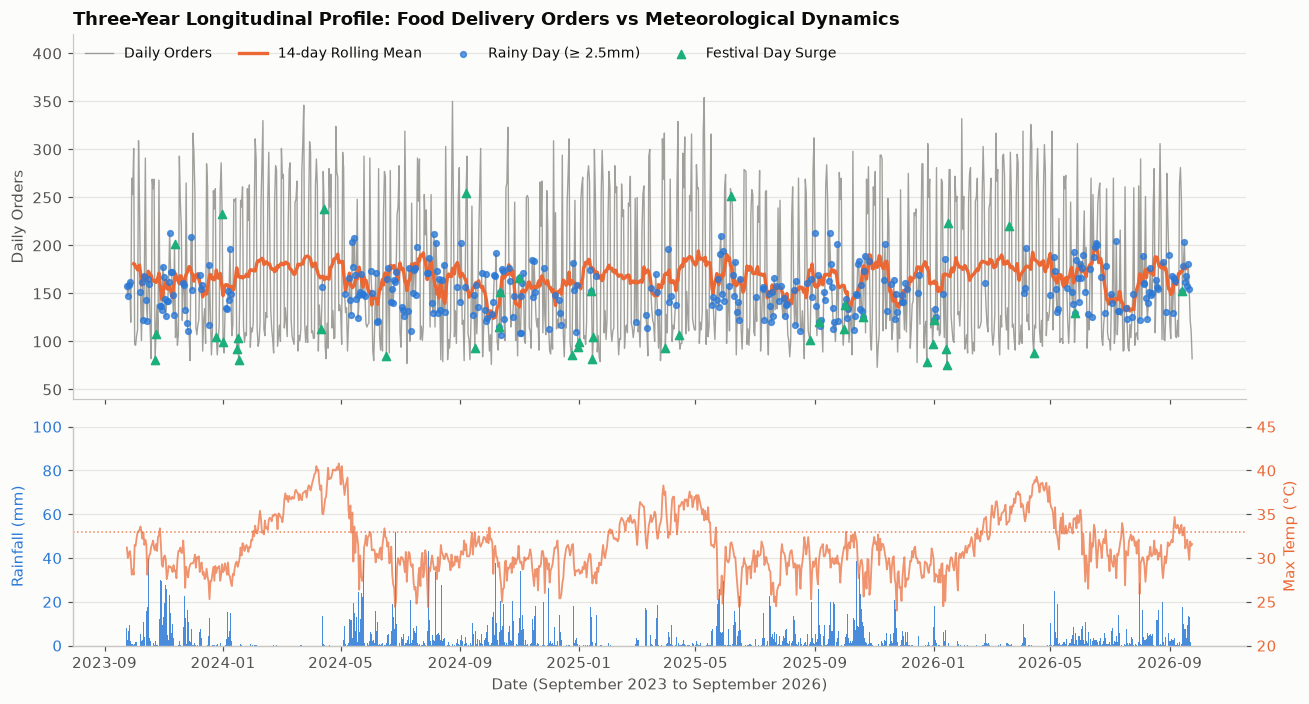

In [19]:
fig10 = eda.plot_fig10_monsoon_timeline(daily, RESULTS / "eda_10_monsoon_timeline.png")
eda.save_fig(fig10, SLIDES_FIGS / "eda_10_monsoon_timeline.png")
plt.show()

### Observations on Longitudinal Trends
* **Stationary Series:** No trend; daily volume moves around ~167 orders/day, driven by the weekly cycle (Fri–Sun peaks), rain (which compresses that cycle) and 41 Tamil Nadu festival days (about x0.89, from the survey).
* **Monsoon Months Look Flatter:** During the SW (Jun–Sep) and NE (Oct–Dec) monsoons rainy days are frequent, so weekday and weekend volumes move closer together.

## 10. Summary of Key Findings & Review 1 Recommendations (T19 & T20)

### 1. Key Analytical Findings
1. **Rain Has Opposite Effects by Day Type:** +54% on Mon–Thu, -47% on Fri–Sun; pooled, rainy days are 10.9% below dry days ($p = 6.0 \times 10^{-9}$). Rain flattens the weekly cycle.
2. **Weekend Lift (~+80% on dry days):** about 124 orders/day Mon–Thu vs about 224 Fri–Sun.
3. **Lunch Dominates:** 73.6% of orders arrive 11:00–16:00; dinner 16.8%, evening snacks 9.7%.
4. **Menu Substitution:** rainy days triple the share of samosa, pakora, bajji, chai and coffee; hot days push cold drinks and ice cream to 47% of items.
5. **Correlations Mislead Here:** pooled $r$ for rain is about $-0.1$ because the weekday and weekend effects cancel.

### 2. Operational Recommendations for Review 1
* **Weather-Aware Staffing:** on a rainy weekday add roughly 50% capacity; on a rainy weekend cut the usual weekend uplift by about half.
* **Dynamic Kitchen Prep:** pre-batch samosa, pakora, bajji and chai/coffee when rain is forecast; stock ice cream, lime juice and cold coffee when the maximum temperature forecast is at least $33^\circ$C.
* **Promotional Bundles:** a rainy-day "Chai + Samosa / Pakora" combo and a hot-day "Ice Cream + Cold Coffee" combo, matching the survey-backed pairs.

---
**All 10 presentation-ready charts have been exported to `results/eda/` and `slides/review1/figures/`.**